# Bone Loss Model Training — ResNet18 with Corrected Imbalance Strategy
## Dental AI Pipeline — Phase 4c

---

### Context
The dataset construction pipeline (notebook 02) produced **22,806 tooth-level crops** with a
**23.84× class imbalance** (96% normal, 4% diseased). This is far more severe than the
1.85× image-level estimate from the project report.

### Strategy
| Step | Action | Why |
|------|--------|-----|
| A | Undersample normals: 17,473 → ~2,500 | Remove redundant healthy tooth crops |
| B | Oversample diseased: 739 → ~1,500 (augmented) | Increase minority diversity |
| C | Focal Loss (γ=2.0) with class weights | Focus on hard cases, not trivially easy normals |

### Inputs
- `processed_dataset_tufts/` from notebook 02 (on Google Drive)
- `metadata/train_metadata.csv` and `val_metadata.csv`

### Outputs
- `resampled_dataset/` — corrected, balanced training set
- `bone_loss_resnet18_best.pth` — best model checkpoint
- Full evaluation report with per-class F1, confusion matrix, failure analysis

---
## Cell 1 — Mount Drive & Verify GPU

In [1]:
from google.colab import drive
drive.mount('/content/drive')

import torch
print(f"PyTorch: {torch.__version__}")
print(f"CUDA available: {torch.cuda.is_available()}")
if torch.cuda.is_available():
    print(f"GPU: {torch.cuda.get_device_name(0)}")
    props = torch.cuda.get_device_properties(0)
    total_mem_bytes = getattr(props, "total_memory", None) or getattr(props, "total_mem", None)
    if total_mem_bytes is not None:
        print(f"Memory: {total_mem_bytes / 1e9:.1f} GB")
    else:
        print("Memory: (unknown)")
else:
    print("⚠️  No GPU detected. Go to Runtime → Change runtime type → T4 GPU")


Mounted at /content/drive
PyTorch: 2.10.0+cu128
CUDA available: True
GPU: Tesla T4
Memory: 15.6 GB


In [2]:
import os
import json
import random
import shutil
import time
import copy
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import cv2
from PIL import Image

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
import torchvision.transforms as transforms
import torchvision.models as models
from sklearn.metrics import (
    f1_score, classification_report, confusion_matrix,
    precision_recall_curve, average_precision_score
)

print("All imports loaded.")

All imports loaded.


---
## Cell 2 — Configuration

In [3]:
# =============================================================================
# PATHS
# =============================================================================
# Source: output from notebook 02 (dataset construction)
SOURCE_DATASET = "/content/drive/MyDrive/tufts/processed_dataset_tufts"

# Corrected resampled dataset (new folder)
RESAMPLED_DIR = "/content/drive/MyDrive/tufts/resampled_dataset"

# Model checkpoints
MODEL_DIR = "/content/drive/MyDrive/tufts/models"

# =============================================================================
# RESAMPLING STRATEGY
# =============================================================================
# Undersample normals to this count (from ~17,473)
NORMAL_TARGET_TRAIN = 2500

# Number of augmented copies per diseased sample
AUGMENT_COPIES = 2  # 739 originals + 739×2 augmented ≈ 2,217 total

# =============================================================================
# TRAINING HYPERPARAMETERS
# =============================================================================
BATCH_SIZE     = 32
LEARNING_RATE  = 1e-4
WEIGHT_DECAY   = 1e-4
NUM_EPOCHS     = 50
NUM_WORKERS    = 2

# Focal Loss
FOCAL_GAMMA    = 2.0     # Focusing parameter
# Alpha will be computed from actual class distribution after resampling

# Early stopping
PATIENCE       = 10

# Scheduler
SCHED_PATIENCE = 5
SCHED_FACTOR   = 0.5

# ImageNet normalization (MUST match across all models in pipeline)
IMAGENET_MEAN  = [0.485, 0.456, 0.406]
IMAGENET_STD   = [0.229, 0.224, 0.225]

CROP_SIZE      = 224
RANDOM_SEED    = 42

# =============================================================================
# EVALUATION TARGETS
# =============================================================================
TARGET_F1_NORMAL   = 0.75
TARGET_F1_DISEASED = 0.70
TARGET_F1_MACRO    = 0.72

# Set seeds
random.seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)
torch.manual_seed(RANDOM_SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(RANDOM_SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Device: {DEVICE}")

# Verify source exists
for split in ['train/0', 'train/1', 'val/0', 'val/1']:
    p = os.path.join(SOURCE_DATASET, split)
    n = len(os.listdir(p)) if os.path.exists(p) else 0
    print(f"  {split}: {n} files")

Device: cuda
  train/0: 7491 files
  train/1: 296 files
  val/0: 0 files
  val/1: 0 files


---
## Cell 3 — Build Corrected Resampled Dataset

This creates a new `resampled_dataset/` folder with:
- **Undersampled normals** (~2,500 from 17,473) — stratified by source image
- **Oversampled diseased** (originals + augmented copies)
- **Validation set kept untouched** (no resampling on val — evaluate on real distribution)

**Critical:** We NEVER resample the validation set. It must reflect the real-world distribution
to give honest evaluation metrics.

In [5]:
from pathlib import Path
import os
import pandas as pd


def _resolve_dataset_root(source_dataset: str) -> Path:
    """Return a dataset root folder that contains train/{0,1}.
    
    If metadata CSVs exist, we'll use them; otherwise we'll build metadata by scanning folders.
    """
    candidates = []

    if source_dataset:
        candidates.append(Path(source_dataset))

    # Common Colab/Drive locations
    candidates += [
        Path("/content/drive/MyDrive/tufts/processed_dataset_tufts"),
        Path("/content/drive/MyDrive/tufts"),
        Path("/content/drive/MyDrive"),
        Path("/content"),
    ]

    required = [Path("train/0"), Path("train/1")]

    # 1) Direct matches
    for root in candidates:
        if all((root / rel).exists() for rel in required):
            return root

    # 2) One-level deep search under likely roots (keeps it fast)
    for base in candidates:
        if not base.exists() or not base.is_dir():
            continue
        try:
            for child in base.iterdir():
                if child.is_dir() and all((child / rel).exists() for rel in required):
                    return child
        except PermissionError:
            continue

    searched = "\n".join(f"- {p}" for p in candidates)
    raise FileNotFoundError(
        "Could not find a dataset folder with train/0 and train/1.\n\n"
        "Expected folders: train/0 and train/1\n\n"
        "Searched these locations (and their immediate subfolders):\n"
        f"{searched}\n\n"
        "Fix: set SOURCE_DATASET to the dataset root folder (the one containing train/0 and train/1)."
    )


def _build_metadata_from_folders(root: Path, split: str) -> pd.DataFrame:
    rows = []
    split_dir = root / split
    for label in [0, 1]:
        cls_dir = split_dir / str(label)
        if not cls_dir.exists():
            continue
        for fname in sorted(os.listdir(cls_dir)):
            if fname.startswith('.') or fname.lower().endswith('.ds_store'):
                continue
            stem_guess = Path(fname).stem
            # Heuristic: many pipelines prefix filename with source image id (stem)
            stem = stem_guess.split('_')[0] if '_' in stem_guess else stem_guess
            rows.append({
                'filename': fname,
                'label': int(label),
                'stem': stem,
            })
    return pd.DataFrame(rows)


def _ensure_train_val_metadata(root: Path, random_seed: int = 42, val_fraction: float = 0.2):
    """Load metadata CSVs if present; otherwise build metadata and (if needed) create a val split."""
    train_csv = root / "metadata" / "train_metadata.csv"
    val_csv = root / "metadata" / "val_metadata.csv"

    if train_csv.exists() and val_csv.exists():
        df_train = pd.read_csv(train_csv)
        df_val = pd.read_csv(val_csv)
        return df_train, df_val, True

    # Build from folders
    df_train_scan = _build_metadata_from_folders(root, "train")
    df_val_scan = _build_metadata_from_folders(root, "val")

    if len(df_train_scan) == 0:
        raise FileNotFoundError(f"No images found under {root}/train/0 or {root}/train/1")

    # If val/ is empty or missing, create a split from train/
    if len(df_val_scan) == 0:
        from sklearn.model_selection import train_test_split
        y = df_train_scan['label'].values
        train_idx, val_idx = train_test_split(
            df_train_scan.index.values,
            test_size=val_fraction,
            random_state=random_seed,
            stratify=y if len(set(y)) > 1 else None,
        )
        df_train = df_train_scan.loc[train_idx].reset_index(drop=True)
        df_val = df_train_scan.loc[val_idx].reset_index(drop=True)
        print(f"⚠️  No val split found on disk; created a {int(val_fraction*100)}% validation split from train/.")
        return df_train, df_val, False

    # Val exists on disk
    return df_train_scan.reset_index(drop=True), df_val_scan.reset_index(drop=True), False


# Load metadata from dataset construction (or build it if missing)
SOURCE_DATASET = str(_resolve_dataset_root(globals().get("SOURCE_DATASET", "")))
print(f"Using SOURCE_DATASET: {SOURCE_DATASET}")

df_train_meta, df_val_meta, loaded_from_csv = _ensure_train_val_metadata(
    Path(SOURCE_DATASET), random_seed=RANDOM_SEED, val_fraction=0.2
 )

print(f"Metadata source: {'CSV files' if loaded_from_csv else 'folder scan / generated split'}")

print(f"Original training set (post-split if generated):")
print(f"  Class 0 (normal):   {(df_train_meta['label']==0).sum()}")
print(f"  Class 1 (diseased): {(df_train_meta['label']==1).sum()}")
print(f"  Ratio: {(df_train_meta['label']==0).sum() / max((df_train_meta['label']==1).sum(),1):.1f}×")

print(f"\nValidation set (untouched on disk if present; otherwise generated):")
print(f"  Class 0: {(df_val_meta['label']==0).sum()}")
print(f"  Class 1: {(df_val_meta['label']==1).sum()}")


Using SOURCE_DATASET: /content/drive/MyDrive/tufts/processed_dataset_tufts
⚠️  No val split found on disk; created a 20% validation split from train/.
Metadata source: folder scan / generated split
Original training set (post-split if generated):
  Class 0 (normal):   5992
  Class 1 (diseased): 237
  Ratio: 25.3×

Validation set (untouched on disk if present; otherwise generated):
  Class 0: 1499
  Class 1: 59


In [6]:
# =============================================================================
# STEP A — Undersample normals (stratified by source image)
# =============================================================================
train_normal = df_train_meta[df_train_meta['label'] == 0].copy()
train_diseased = df_train_meta[df_train_meta['label'] == 1].copy()

# Stratified undersample: proportional samples from each source image
normal_per_image = train_normal.groupby('stem', group_keys=False).apply(
    lambda g: g.sample(
        n=min(
            len(g),
            max(1, int(NORMAL_TARGET_TRAIN * len(g) / len(train_normal)))
        ),
        random_state=RANDOM_SEED
    )
)

# Adjust to hit target (proportional sampling may undershoot/overshoot slightly)
if len(normal_per_image) < NORMAL_TARGET_TRAIN:
    remaining = train_normal.drop(index=normal_per_image.index, errors='ignore')
    extra = remaining.sample(
        n=min(NORMAL_TARGET_TRAIN - len(normal_per_image), len(remaining)),
        random_state=RANDOM_SEED
    )
    normal_per_image = pd.concat([normal_per_image, extra], axis=0)
elif len(normal_per_image) > NORMAL_TARGET_TRAIN:
    normal_per_image = normal_per_image.sample(n=NORMAL_TARGET_TRAIN, random_state=RANDOM_SEED)

normal_per_image = normal_per_image.reset_index(drop=True)

print(f"[A] Undersampled normals: {len(train_normal)} → {len(normal_per_image)}")
print(f"    From {normal_per_image['stem'].nunique()} unique images (preserving diversity)")


[A] Undersampled normals: 5992 → 2500
    From 145 unique images (preserving diversity)


/tmp/ipykernel_13591/2068622626.py:8: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  normal_per_image = train_normal.groupby('stem', group_keys=False).apply(


In [7]:
# =============================================================================
# STEP B — Create resampled dataset on disk
# =============================================================================

# Augmentation transforms for diseased oversampling
augment_transform = transforms.Compose([
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=10),
    transforms.ColorJitter(brightness=0.2, contrast=0.1),
    transforms.RandomAffine(degrees=0, translate=(0.05, 0.05)),
])

# Clean output
if os.path.exists(RESAMPLED_DIR):
    shutil.rmtree(RESAMPLED_DIR)

for split in ['train', 'val']:
    for cls in ['0', '1']:
        os.makedirs(os.path.join(RESAMPLED_DIR, split, cls), exist_ok=True)
os.makedirs(os.path.join(RESAMPLED_DIR, 'metadata'), exist_ok=True)

resampled_meta_rows = []

def copy_crop(src_dir, filename, label, dst_dir, new_filename=None):
    """Copy a crop file from source to destination."""
    src = os.path.join(src_dir, str(label), filename)
    dst_name = new_filename or filename
    dst = os.path.join(dst_dir, str(label), dst_name)
    if os.path.exists(src):
        shutil.copy2(src, dst)
        return True
    return False

src_train_dir = os.path.join(SOURCE_DATASET, 'train')
dst_train_dir = os.path.join(RESAMPLED_DIR, 'train')

# --- Copy undersampled normals ---
copied_normal = 0
for _, row in normal_per_image.iterrows():
    if copy_crop(src_train_dir, row['filename'], 0, dst_train_dir):
        resampled_meta_rows.append({**row.to_dict(), 'augmented': False})
        copied_normal += 1

print(f"Copied {copied_normal} undersampled normal crops")

# --- Copy ALL original diseased + generate augmented copies ---
copied_diseased = 0
augmented_diseased = 0

for _, row in train_diseased.iterrows():
    # Copy original
    if copy_crop(src_train_dir, row['filename'], 1, dst_train_dir):
        resampled_meta_rows.append({**row.to_dict(), 'augmented': False})
        copied_diseased += 1

        # Generate augmented copies
        src_path = os.path.join(src_train_dir, '1', row['filename'])
        if os.path.exists(src_path):
            img = Image.open(src_path).convert('RGB')

            for aug_i in range(AUGMENT_COPIES):
                aug_img = augment_transform(img)
                aug_fname = f"aug{aug_i}_{row['filename']}"
                aug_path = os.path.join(dst_train_dir, '1', aug_fname)
                aug_img.save(aug_path)

                aug_row = row.to_dict()
                aug_row['filename'] = aug_fname
                aug_row['augmented'] = True
                resampled_meta_rows.append(aug_row)
                augmented_diseased += 1

print(f"Copied {copied_diseased} original diseased crops")
print(f"Generated {augmented_diseased} augmented diseased copies")

# --- Copy validation set AS-IS if present on disk; otherwise use generated df_val_meta ---
src_val_dir = os.path.join(SOURCE_DATASET, 'val')
dst_val_dir = os.path.join(RESAMPLED_DIR, 'val')

def _split_has_files(root_dir: str) -> bool:
    if not os.path.exists(root_dir):
        return False
    for cls in ['0', '1']:
        cls_dir = os.path.join(root_dir, cls)
        if os.path.exists(cls_dir) and len([f for f in os.listdir(cls_dir) if not f.startswith('.')]) > 0:
            return True
    return False

val_copied = 0
if _split_has_files(src_val_dir):
    # Copy from existing val folders
    for cls in ['0', '1']:
        src_cls = os.path.join(src_val_dir, cls)
        dst_cls = os.path.join(dst_val_dir, cls)
        if os.path.exists(src_cls):
            for f in os.listdir(src_cls):
                if f.startswith('.') or f.lower().endswith('.ds_store'):
                    continue
                shutil.copy2(os.path.join(src_cls, f), os.path.join(dst_cls, f))
                val_copied += 1
    print(f"Copied {val_copied} validation crops from SOURCE_DATASET/val (untouched)")
else:
    # Copy using generated validation metadata (from SOURCE_DATASET/train)
    for _, row in df_val_meta.iterrows():
        if copy_crop(src_train_dir, row['filename'], int(row['label']), dst_val_dir):
            val_copied += 1
    print(f"Copied {val_copied} validation crops from generated split (source: SOURCE_DATASET/train)")

# Save resampled metadata
df_resampled_meta = pd.DataFrame(resampled_meta_rows)
df_resampled_meta.to_csv(os.path.join(RESAMPLED_DIR, 'metadata', 'train_resampled_metadata.csv'), index=False)

# Save validation metadata (generated or loaded)
df_val_meta.to_csv(os.path.join(RESAMPLED_DIR, 'metadata', 'val_metadata.csv'), index=False)


Copied 2500 undersampled normal crops
Copied 237 original diseased crops
Generated 474 augmented diseased copies
Copied 1558 validation crops from generated split (source: SOURCE_DATASET/train)


In [8]:
# =============================================================================
# VERIFY RESAMPLED DATASET
# =============================================================================
print("=" * 55)
print("RESAMPLED DATASET SUMMARY")
print("=" * 55)

for split in ['train', 'val']:
    for cls in ['0', '1']:
        folder = os.path.join(RESAMPLED_DIR, split, cls)
        n = len(os.listdir(folder))
        print(f"  {split}/{cls}: {n} crops")

train_0 = len(os.listdir(os.path.join(RESAMPLED_DIR, 'train', '0')))
train_1 = len(os.listdir(os.path.join(RESAMPLED_DIR, 'train', '1')))
ratio = train_0 / max(train_1, 1)

print(f"\n  Train ratio: {ratio:.2f}× (target: ~1.5-2.0×)")
print(f"  Val: untouched (real-world distribution)")
print(f"\n  Saved to: {RESAMPLED_DIR}")
print("=" * 55)

RESAMPLED DATASET SUMMARY
  train/0: 2500 crops
  train/1: 711 crops
  val/0: 1499 crops
  val/1: 59 crops

  Train ratio: 3.52× (target: ~1.5-2.0×)
  Val: untouched (real-world distribution)

  Saved to: /content/drive/MyDrive/tufts/resampled_dataset


---
## Cell 4 — Dataset Class & DataLoaders

In [9]:
class BoneLossDataset(Dataset):
    """
    PyTorch Dataset for bone loss classification.
    Loads 224×224 tooth crops from class-wise folders.

    Normalization: ImageNet mean/std (MUST match caries pipeline).
    """
    def __init__(self, root_dir, transform=None):
        self.root_dir = root_dir
        self.transform = transform
        self.samples = []  # (filepath, label)

        for cls in [0, 1]:
            cls_dir = os.path.join(root_dir, str(cls))
            if not os.path.exists(cls_dir):
                continue
            for fname in sorted(os.listdir(cls_dir)):
                self.samples.append((os.path.join(cls_dir, fname), cls))

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, idx):
        path, label = self.samples[idx]
        # Load as RGB (ResNet expects 3 channels)
        image = Image.open(path).convert('RGB')

        if self.transform:
            image = self.transform(image)

        return image, label


# --- Transforms ---
# Training: augmentation + normalization
train_transform = transforms.Compose([
    transforms.Resize((CROP_SIZE, CROP_SIZE)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=10),
    transforms.ColorJitter(brightness=0.2, contrast=0.1),
    transforms.ToTensor(),
    transforms.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD),
])

# Validation: ONLY normalization (no augmentation)
val_transform = transforms.Compose([
    transforms.Resize((CROP_SIZE, CROP_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD),
])

# --- Create datasets ---
train_dataset = BoneLossDataset(
    os.path.join(RESAMPLED_DIR, 'train'), transform=train_transform
)
val_dataset = BoneLossDataset(
    os.path.join(RESAMPLED_DIR, 'val'), transform=val_transform
)

# --- DataLoaders ---
train_loader = DataLoader(
    train_dataset, batch_size=BATCH_SIZE, shuffle=True,
    num_workers=NUM_WORKERS, pin_memory=True
)
val_loader = DataLoader(
    val_dataset, batch_size=BATCH_SIZE, shuffle=False,
    num_workers=NUM_WORKERS, pin_memory=True
)

# --- Report ---
train_labels = [s[1] for s in train_dataset.samples]
val_labels = [s[1] for s in val_dataset.samples]

print(f"Train: {len(train_dataset)} samples ({Counter(train_labels)})")
print(f"Val:   {len(val_dataset)} samples ({Counter(val_labels)})")
print(f"Batches per epoch: {len(train_loader)} train, {len(val_loader)} val")

Train: 3211 samples (Counter({0: 2500, 1: 711}))
Val:   1558 samples (Counter({0: 1499, 1: 59}))
Batches per epoch: 101 train, 49 val


---
## Cell 5 — Focal Loss Implementation

Standard CrossEntropy treats all samples equally. With 96% normals, the gradient is
dominated by trivially easy healthy teeth.

**Focal Loss** adds a modulating factor `(1 - p_t)^γ` that:
- Down-weights well-classified easy samples (most normals)
- Focuses learning on hard, misclassified borderline cases
- Combined with α-weighting for remaining class imbalance

In [10]:
class FocalLoss(nn.Module):
    """
    Focal Loss for binary/multi-class classification.

    FL(p_t) = -α_t × (1 - p_t)^γ × log(p_t)

    Args:
        alpha: Per-class weight tensor. Compensates residual imbalance
               after resampling.
        gamma: Focusing parameter (default 2.0).
               γ=0 → standard cross-entropy
               γ=2 → strong focus on hard cases
    """
    def __init__(self, alpha=None, gamma=2.0, reduction='mean'):
        super().__init__()
        self.gamma = gamma
        self.reduction = reduction

        if alpha is not None:
            if isinstance(alpha, (list, np.ndarray)):
                self.alpha = torch.tensor(alpha, dtype=torch.float32)
            else:
                self.alpha = alpha
        else:
            self.alpha = None

    def forward(self, inputs, targets):
        ce_loss = nn.functional.cross_entropy(
            inputs, targets, reduction='none'
        )
        pt = torch.exp(-ce_loss)  # p_t = probability of correct class
        focal_weight = (1 - pt) ** self.gamma

        loss = focal_weight * ce_loss

        # Apply alpha weighting
        if self.alpha is not None:
            alpha = self.alpha.to(inputs.device)
            alpha_t = alpha[targets]
            loss = alpha_t * loss

        if self.reduction == 'mean':
            return loss.mean()
        elif self.reduction == 'sum':
            return loss.sum()
        return loss


# Compute alpha from resampled training distribution
train_counts = Counter(train_labels)
n_total = len(train_labels)
n_classes = 2

# Balanced class weights: total / (n_classes × count_per_class)
alpha_0 = n_total / (n_classes * train_counts[0])
alpha_1 = n_total / (n_classes * train_counts[1])
alpha_weights = [alpha_0, alpha_1]

print(f"Class distribution in resampled train: {dict(train_counts)}")
print(f"Focal Loss α weights: [{alpha_0:.3f}, {alpha_1:.3f}]")
print(f"Focal Loss γ: {FOCAL_GAMMA}")

criterion = FocalLoss(alpha=alpha_weights, gamma=FOCAL_GAMMA)
print(f"\nLoss function: FocalLoss(α={[round(a,3) for a in alpha_weights]}, γ={FOCAL_GAMMA})")

Class distribution in resampled train: {0: 2500, 1: 711}
Focal Loss α weights: [0.642, 2.258]
Focal Loss γ: 2.0

Loss function: FocalLoss(α=[0.642, 2.258], γ=2.0)


---
## Cell 6 — Model Architecture

ResNet18 pretrained on ImageNet. Replace final FC layer: 512 → 2 (binary).

Same architecture as caries pipeline (Phase 1 & 2) for consistency.

In [11]:
def build_model(num_classes=2, pretrained=True):
    """
    ResNet18 with replaced FC layer for binary classification.

    Pretrained on ImageNet → fine-tuned on dental crops.
    """
    weights = None
    if pretrained:
        # Robust across torchvision versions
        try:
            weights = models.ResNet18_Weights.IMAGENET1K_V1
        except Exception:
            weights = 'IMAGENET1K_V1'
    model = models.resnet18(weights=weights)

    # Replace final FC: 512 → num_classes
    in_features = model.fc.in_features
    model.fc = nn.Linear(in_features, num_classes)

    return model


model = build_model(num_classes=2, pretrained=True)
model = model.to(DEVICE)

# Count parameters
total_params = sum(p.numel() for p in model.parameters())
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"Model: ResNet18")
print(f"  FC layer: {model.fc.in_features} → {model.fc.out_features}")
print(f"  Total params: {total_params:,}")
print(f"  Trainable: {trainable_params:,}")


Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 173MB/s]


Model: ResNet18
  FC layer: 512 → 2
  Total params: 11,177,538
  Trainable: 11,177,538


In [13]:
# Optimizer & Scheduler
optimizer = optim.Adam(
    model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY
)

# ReduceLROnPlateau has slightly different signatures across PyTorch versions;
# make this compatible by falling back if 'verbose' isn't supported.
try:
    scheduler = optim.lr_scheduler.ReduceLROnPlateau(
        optimizer, mode='max', factor=SCHED_FACTOR,
        patience=SCHED_PATIENCE, verbose=True
    )
except TypeError:
    scheduler = optim.lr_scheduler.ReduceLROnPlateau(
        optimizer, mode='max', factor=SCHED_FACTOR,
        patience=SCHED_PATIENCE
    )

print(f"Optimizer: Adam (lr={LEARNING_RATE}, wd={WEIGHT_DECAY})")
print(f"Scheduler: ReduceLROnPlateau (patience={SCHED_PATIENCE}, factor={SCHED_FACTOR})")
print(f"Early stopping: patience={PATIENCE}, monitor=val_f1_macro")


Optimizer: Adam (lr=0.0001, wd=0.0001)
Scheduler: ReduceLROnPlateau (patience=5, factor=0.5)
Early stopping: patience=10, monitor=val_f1_macro


---
## Cell 7 — Training Loop

In [14]:
def train_one_epoch(model, loader, criterion, optimizer, device):
    """Train for one epoch. Returns avg loss."""
    model.train()
    running_loss = 0.0
    n_batches = 0

    for images, labels in loader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        running_loss += loss.item()
        n_batches += 1

    return running_loss / n_batches


def evaluate(model, loader, criterion, device):
    """Evaluate on validation set. Returns loss, predictions, true labels."""
    model.eval()
    running_loss = 0.0
    n_batches = 0
    all_preds = []
    all_labels = []
    all_probs = []

    with torch.no_grad():
        for images, labels in loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)
            loss = criterion(outputs, labels)

            probs = torch.softmax(outputs, dim=1)
            preds = outputs.argmax(dim=1)

            running_loss += loss.item()
            n_batches += 1
            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())
            all_probs.extend(probs[:, 1].cpu().numpy())  # P(diseased)

    avg_loss = running_loss / n_batches
    return avg_loss, np.array(all_preds), np.array(all_labels), np.array(all_probs)


print("Training and evaluation functions defined.")

Training and evaluation functions defined.


In [15]:
# =============================================================================
# MAIN TRAINING LOOP
# =============================================================================
os.makedirs(MODEL_DIR, exist_ok=True)

history = {
    'train_loss': [], 'val_loss': [],
    'val_f1_macro': [], 'val_f1_class0': [], 'val_f1_class1': [],
    'val_accuracy': [], 'lr': [],
}

best_f1 = 0.0
best_epoch = 0
epochs_no_improve = 0
best_model_state = None

print("=" * 70)
print(f"{'Epoch':>5} | {'Train Loss':>10} | {'Val Loss':>8} | "
      f"{'F1-Norm':>7} | {'F1-Dis':>6} | {'F1-Mac':>6} | {'LR':>9}")
print("-" * 70)

start_time = time.time()

for epoch in range(1, NUM_EPOCHS + 1):
    # Train
    train_loss = train_one_epoch(model, train_loader, criterion, optimizer, DEVICE)

    # Evaluate
    val_loss, val_preds, val_labels_arr, val_probs = evaluate(
        model, val_loader, criterion, DEVICE
    )

    # Metrics
    f1_per_class = f1_score(val_labels_arr, val_preds, average=None, zero_division=0)
    f1_macro = f1_score(val_labels_arr, val_preds, average='macro', zero_division=0)
    accuracy = (val_preds == val_labels_arr).mean()

    f1_c0 = f1_per_class[0] if len(f1_per_class) > 0 else 0
    f1_c1 = f1_per_class[1] if len(f1_per_class) > 1 else 0
    current_lr = optimizer.param_groups[0]['lr']

    # Record history
    history['train_loss'].append(train_loss)
    history['val_loss'].append(val_loss)
    history['val_f1_macro'].append(f1_macro)
    history['val_f1_class0'].append(f1_c0)
    history['val_f1_class1'].append(f1_c1)
    history['val_accuracy'].append(accuracy)
    history['lr'].append(current_lr)

    # Check for improvement
    improved = ""
    if f1_macro > best_f1:
        best_f1 = f1_macro
        best_epoch = epoch
        best_model_state = copy.deepcopy(model.state_dict())
        epochs_no_improve = 0
        improved = " ★"
    else:
        epochs_no_improve += 1

    # Print
    print(f"{epoch:5d} | {train_loss:10.4f} | {val_loss:8.4f} | "
          f"{f1_c0:7.4f} | {f1_c1:6.4f} | {f1_macro:6.4f} | "
          f"{current_lr:.2e}{improved}")

    # Scheduler step (monitor val F1 macro)
    scheduler.step(f1_macro)

    # Early stopping
    if epochs_no_improve >= PATIENCE:
        print(f"\n  Early stopping at epoch {epoch} (no improvement for {PATIENCE} epochs)")
        break

elapsed = time.time() - start_time
print("-" * 70)
print(f"Training complete in {elapsed/60:.1f} min")
print(f"Best epoch: {best_epoch} (F1 macro = {best_f1:.4f})")

Epoch | Train Loss | Val Loss | F1-Norm | F1-Dis | F1-Mac |        LR
----------------------------------------------------------------------
    1 |     0.1264 |   0.0641 |  0.9782 | 0.2500 | 0.6141 | 1.00e-04 ★
    2 |     0.0738 |   0.0654 |  0.9535 | 0.2990 | 0.6262 | 1.00e-04 ★
    3 |     0.0529 |   0.0607 |  0.9744 | 0.4722 | 0.7233 | 1.00e-04 ★
    4 |     0.0442 |   0.0585 |  0.9752 | 0.4638 | 0.7195 | 1.00e-04
    5 |     0.0284 |   0.0573 |  0.9734 | 0.4698 | 0.7216 | 1.00e-04
    6 |     0.0354 |   0.0604 |  0.9793 | 0.5000 | 0.7396 | 1.00e-04 ★
    7 |     0.0264 |   0.0420 |  0.9836 | 0.6202 | 0.8019 | 1.00e-04 ★
    8 |     0.0183 |   0.0559 |  0.9743 | 0.5366 | 0.7554 | 1.00e-04
    9 |     0.0185 |   0.0554 |  0.9768 | 0.5306 | 0.7537 | 1.00e-04
   10 |     0.0156 |   0.0328 |  0.9811 | 0.6164 | 0.7988 | 1.00e-04
   11 |     0.0127 |   0.0702 |  0.9496 | 0.3882 | 0.6689 | 1.00e-04
   12 |     0.0164 |   0.0399 |  0.9849 | 0.6667 | 0.8258 | 1.00e-04 ★
   13 |     0.0130 

In [16]:
# =============================================================================
# SAVE BEST MODEL + TRAINING HISTORY
# =============================================================================
best_model_path = os.path.join(MODEL_DIR, 'bone_loss_resnet18_best.pth')
torch.save(best_model_state, best_model_path)
print(f"Best model saved: {best_model_path}")

# Save final model too
final_model_path = os.path.join(MODEL_DIR, 'bone_loss_resnet18_final.pth')
torch.save(model.state_dict(), final_model_path)
print(f"Final model saved: {final_model_path}")

# Save history
history_path = os.path.join(MODEL_DIR, 'training_history.json')
with open(history_path, 'w') as f:
    json.dump(history, f, indent=2)
print(f"History saved: {history_path}")

Best model saved: /content/drive/MyDrive/tufts/models/bone_loss_resnet18_best.pth
Final model saved: /content/drive/MyDrive/tufts/models/bone_loss_resnet18_final.pth
History saved: /content/drive/MyDrive/tufts/models/training_history.json


---
## Cell 8 — Training Curves

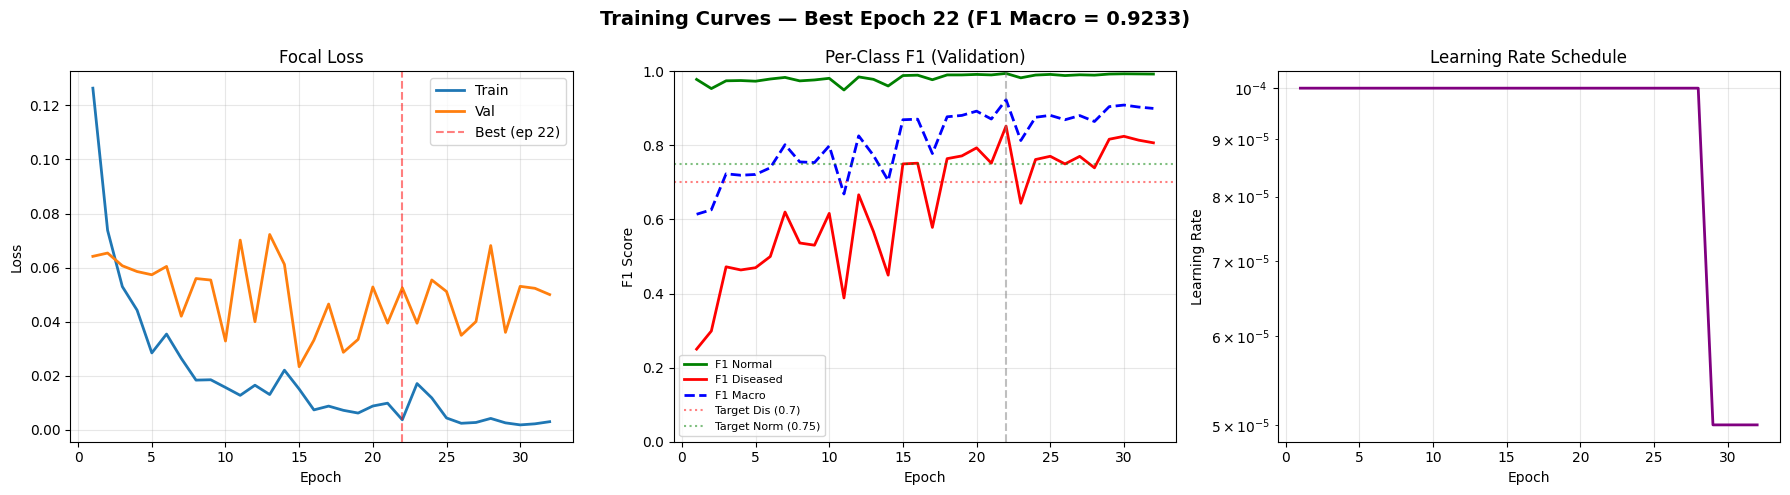

In [17]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

epochs_range = range(1, len(history['train_loss']) + 1)

# (a) Loss
axes[0].plot(epochs_range, history['train_loss'], label='Train', linewidth=2)
axes[0].plot(epochs_range, history['val_loss'], label='Val', linewidth=2)
axes[0].axvline(best_epoch, color='red', ls='--', alpha=0.5, label=f'Best (ep {best_epoch})')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Loss')
axes[0].set_title('Focal Loss')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# (b) Per-class F1
axes[1].plot(epochs_range, history['val_f1_class0'], label='F1 Normal', linewidth=2, color='green')
axes[1].plot(epochs_range, history['val_f1_class1'], label='F1 Diseased', linewidth=2, color='red')
axes[1].plot(epochs_range, history['val_f1_macro'], label='F1 Macro', linewidth=2, color='blue', ls='--')
axes[1].axhline(TARGET_F1_DISEASED, color='red', ls=':', alpha=0.5, label=f'Target Dis ({TARGET_F1_DISEASED})')
axes[1].axhline(TARGET_F1_NORMAL, color='green', ls=':', alpha=0.5, label=f'Target Norm ({TARGET_F1_NORMAL})')
axes[1].axvline(best_epoch, color='gray', ls='--', alpha=0.5)
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('F1 Score')
axes[1].set_title('Per-Class F1 (Validation)')
axes[1].legend(fontsize=8)
axes[1].set_ylim([0, 1])
axes[1].grid(True, alpha=0.3)

# (c) Learning rate
axes[2].plot(epochs_range, history['lr'], linewidth=2, color='purple')
axes[2].set_xlabel('Epoch')
axes[2].set_ylabel('Learning Rate')
axes[2].set_title('Learning Rate Schedule')
axes[2].set_yscale('log')
axes[2].grid(True, alpha=0.3)

plt.suptitle(f'Training Curves — Best Epoch {best_epoch} (F1 Macro = {best_f1:.4f})',
             fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig(os.path.join(MODEL_DIR, 'training_curves.png'), dpi=150, bbox_inches='tight')
plt.show()

---
## Cell 9 — Final Evaluation (Best Model)

Load best checkpoint and evaluate on the **untouched** validation set.

In [18]:
# Load best model
model.load_state_dict(best_model_state)
model.eval()

# Final evaluation
val_loss, val_preds, val_true, val_probs = evaluate(
    model, val_loader, criterion, DEVICE
)

# Classification report
print("=" * 55)
print(f"FINAL EVALUATION — Best Model (Epoch {best_epoch})")
print("=" * 55)
print(f"\nValidation set: {len(val_true)} samples (real-world distribution)")
print(f"  Class 0 (normal):   {(val_true==0).sum()}")
print(f"  Class 1 (diseased): {(val_true==1).sum()}")
print()

report = classification_report(
    val_true, val_preds,
    target_names=['Normal', 'Diseased'],
    digits=4, zero_division=0
)
print(report)

# Check against targets
f1_per = f1_score(val_true, val_preds, average=None, zero_division=0)
f1_mac = f1_score(val_true, val_preds, average='macro', zero_division=0)

f1_c0 = f1_per[0] if len(f1_per) > 0 else 0
f1_c1 = f1_per[1] if len(f1_per) > 1 else 0

print(f"Target Check:")
print(f"  F1 Normal:   {f1_c0:.4f}  {'✓ PASS' if f1_c0 >= TARGET_F1_NORMAL else '✗ BELOW TARGET'}  (target ≥ {TARGET_F1_NORMAL})")
print(f"  F1 Diseased: {f1_c1:.4f}  {'✓ PASS' if f1_c1 >= TARGET_F1_DISEASED else '✗ BELOW TARGET'}  (target ≥ {TARGET_F1_DISEASED})")
print(f"  F1 Macro:    {f1_mac:.4f}  {'✓ PASS' if f1_mac >= TARGET_F1_MACRO else '✗ BELOW TARGET'}  (target ≥ {TARGET_F1_MACRO})")

FINAL EVALUATION — Best Model (Epoch 22)

Validation set: 1558 samples (real-world distribution)
  Class 0 (normal):   1499
  Class 1 (diseased): 59

              precision    recall  f1-score   support

      Normal     0.9933    0.9953    0.9943      1499
    Diseased     0.8750    0.8305    0.8522        59

    accuracy                         0.9891      1558
   macro avg     0.9342    0.9129    0.9233      1558
weighted avg     0.9889    0.9891    0.9890      1558

Target Check:
  F1 Normal:   0.9943  ✓ PASS  (target ≥ 0.75)
  F1 Diseased: 0.8522  ✓ PASS  (target ≥ 0.7)
  F1 Macro:    0.9233  ✓ PASS  (target ≥ 0.72)


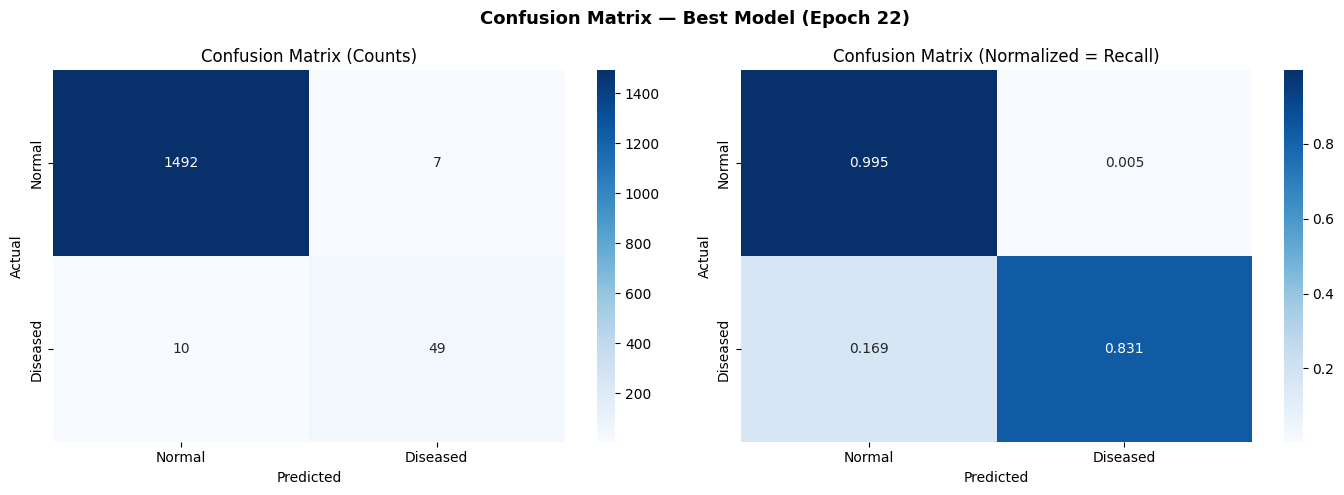


Breakdown:
  True Negatives  (correctly normal):   1492
  False Positives (false alarm):         7
  False Negatives (missed bone loss):    10
  True Positives  (correctly detected):  49

  Sensitivity (recall for diseased): 0.8305
  Specificity (recall for normal):   0.9953


In [19]:
# =============================================================================
# CONFUSION MATRIX
# =============================================================================
cm = confusion_matrix(val_true, val_preds)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Raw counts
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[0],
            xticklabels=['Normal', 'Diseased'],
            yticklabels=['Normal', 'Diseased'])
axes[0].set_xlabel('Predicted')
axes[0].set_ylabel('Actual')
axes[0].set_title('Confusion Matrix (Counts)')

# Normalized (per-row = recall)
cm_norm = cm.astype(float) / cm.sum(axis=1, keepdims=True)
sns.heatmap(cm_norm, annot=True, fmt='.3f', cmap='Blues', ax=axes[1],
            xticklabels=['Normal', 'Diseased'],
            yticklabels=['Normal', 'Diseased'])
axes[1].set_xlabel('Predicted')
axes[1].set_ylabel('Actual')
axes[1].set_title('Confusion Matrix (Normalized = Recall)')

plt.suptitle(f'Confusion Matrix — Best Model (Epoch {best_epoch})', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig(os.path.join(MODEL_DIR, 'confusion_matrix.png'), dpi=150, bbox_inches='tight')
plt.show()

# Interpret
tn, fp, fn, tp = cm.ravel()
print(f"\nBreakdown:")
print(f"  True Negatives  (correctly normal):   {tn}")
print(f"  False Positives (false alarm):         {fp}")
print(f"  False Negatives (missed bone loss):    {fn}")
print(f"  True Positives  (correctly detected):  {tp}")
print(f"\n  Sensitivity (recall for diseased): {tp/(tp+fn):.4f}" if (tp+fn)>0 else "")
print(f"  Specificity (recall for normal):   {tn/(tn+fp):.4f}" if (tn+fp)>0 else "")

---
## Cell 10 — Failure Analysis

Understanding **what the model gets wrong** is as important as the metrics.

False Positives (predicted diseased, actually normal): 7
False Negatives (predicted normal, actually diseased): 10
True Positives:  49


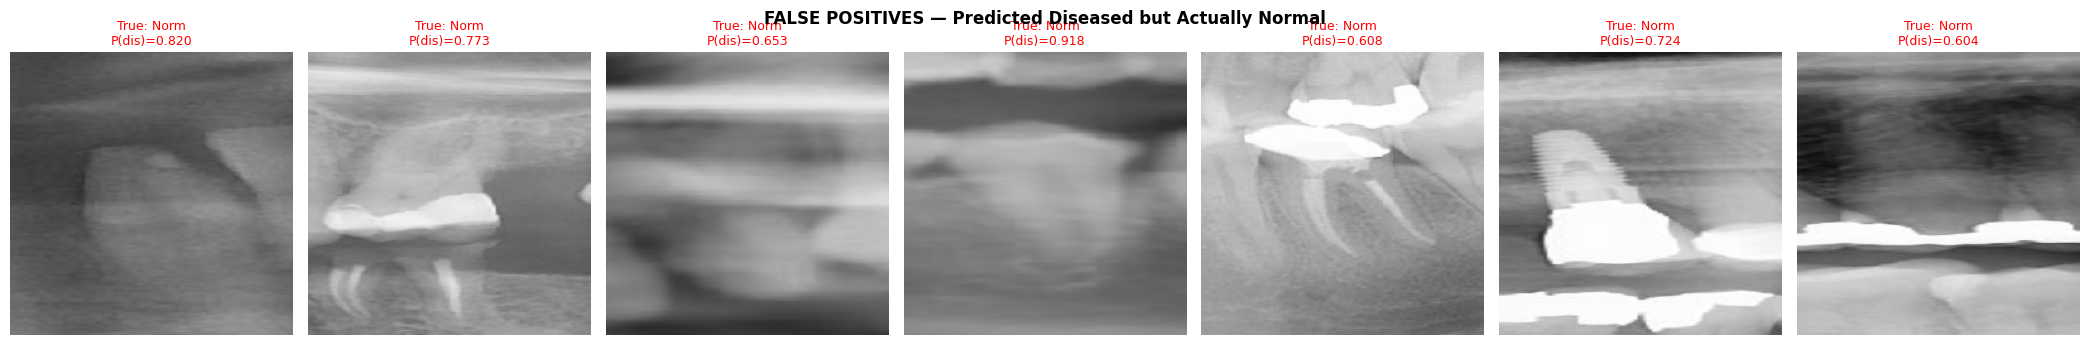

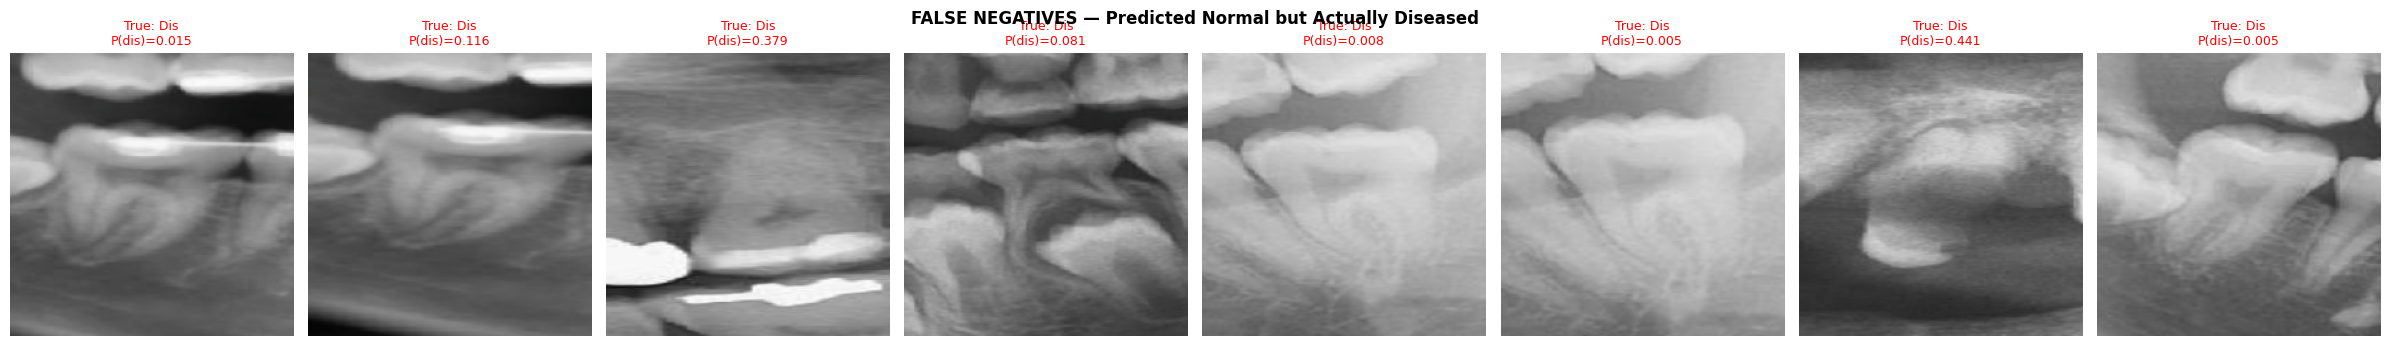

In [20]:
# Identify false positives and false negatives
fp_indices = np.where((val_preds == 1) & (val_true == 0))[0]
fn_indices = np.where((val_preds == 0) & (val_true == 1))[0]
tp_indices = np.where((val_preds == 1) & (val_true == 1))[0]

print(f"False Positives (predicted diseased, actually normal): {len(fp_indices)}")
print(f"False Negatives (predicted normal, actually diseased): {len(fn_indices)}")
print(f"True Positives:  {len(tp_indices)}")

# Inverse normalization for display
inv_normalize = transforms.Compose([
    transforms.Normalize(
        mean=[-m/s for m, s in zip(IMAGENET_MEAN, IMAGENET_STD)],
        std=[1/s for s in IMAGENET_STD]
    )
])


def show_failure_cases(indices, title, max_show=8):
    """Display misclassified samples with their predicted probabilities."""
    n_show = min(len(indices), max_show)
    if n_show == 0:
        print(f"  No {title} to show.")
        return

    fig, axes = plt.subplots(1, n_show, figsize=(3 * n_show, 3.5))
    if n_show == 1:
        axes = [axes]

    for i, idx in enumerate(indices[:n_show]):
        img_tensor, label = val_dataset[idx]
        img = inv_normalize(img_tensor)
        img = img.permute(1, 2, 0).numpy()
        img = np.clip(img, 0, 1)

        axes[i].imshow(img)
        pred_prob = val_probs[idx]
        axes[i].set_title(
            f"True: {'Dis' if label==1 else 'Norm'}\n"
            f"P(dis)={pred_prob:.3f}",
            fontsize=9, color='red'
        )
        axes[i].axis('off')

    plt.suptitle(title, fontsize=12, fontweight='bold')
    plt.tight_layout()
    plt.show()


show_failure_cases(fp_indices, 'FALSE POSITIVES — Predicted Diseased but Actually Normal')
show_failure_cases(fn_indices, 'FALSE NEGATIVES — Predicted Normal but Actually Diseased')

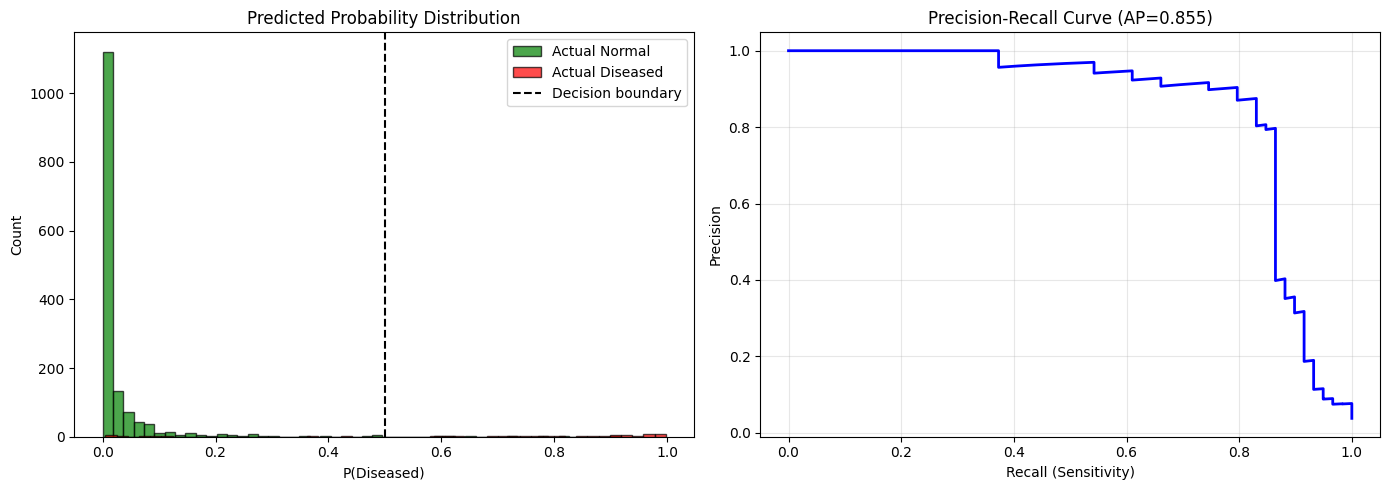

In [21]:
# =============================================================================
# PROBABILITY DISTRIBUTION ANALYSIS
# =============================================================================
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# P(diseased) for actual normals vs actual diseased
probs_normal = val_probs[val_true == 0]
probs_diseased = val_probs[val_true == 1]

axes[0].hist(probs_normal, bins=50, alpha=0.7, label='Actual Normal', color='green', edgecolor='black')
axes[0].hist(probs_diseased, bins=50, alpha=0.7, label='Actual Diseased', color='red', edgecolor='black')
axes[0].axvline(0.5, color='black', ls='--', label='Decision boundary')
axes[0].set_xlabel('P(Diseased)')
axes[0].set_ylabel('Count')
axes[0].set_title('Predicted Probability Distribution')
axes[0].legend()

# Precision-Recall curve
if len(np.unique(val_true)) > 1:
    precision, recall, thresholds = precision_recall_curve(val_true, val_probs)
    ap = average_precision_score(val_true, val_probs)
    axes[1].plot(recall, precision, linewidth=2, color='blue')
    axes[1].set_xlabel('Recall (Sensitivity)')
    axes[1].set_ylabel('Precision')
    axes[1].set_title(f'Precision-Recall Curve (AP={ap:.3f})')
    axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(os.path.join(MODEL_DIR, 'probability_analysis.png'), dpi=150, bbox_inches='tight')
plt.show()

---
## Cell 11 — Complete Summary

In [22]:
summary = f"""
{'='*65}
 BONE LOSS MODEL — COMPLETE TRAINING SUMMARY
{'='*65}

PROJECT:  Dental AI Pipeline — Phase 4c (Bone Loss Detection)
MODEL:    ResNet18 pretrained on ImageNet, fine-tuned
TASK:     Binary classification — bone loss present / absent
INPUT:    224×224 expanded crop (1.5× W, 2.0× H)

{'—'*65}
 DATASET
{'—'*65}

Source (from notebook 02):
  Total crops:          22,806
  Original imbalance:   23.84× (96% normal, 4% diseased)

Resampled (corrected):
  Train normal:         {len(os.listdir(os.path.join(RESAMPLED_DIR,'train','0')))} (undersampled from 17,473)
  Train diseased:       {len(os.listdir(os.path.join(RESAMPLED_DIR,'train','1')))} (originals + {AUGMENT_COPIES}× augmented)
  Train total:          {len(train_dataset)}
  Train ratio:          {Counter(train_labels)[0]/max(Counter(train_labels)[1],1):.2f}×
  Val normal:           {(val_true==0).sum()} (untouched)
  Val diseased:         {(val_true==1).sum()} (untouched)
  Val total:            {len(val_true)}

Resampled dataset saved to:
  {RESAMPLED_DIR}

{'—'*65}
 TRAINING CONFIGURATION
{'—'*65}

  Architecture:         ResNet18 (pretrained ImageNet)
  FC layer:             512 → 2
  Loss:                 FocalLoss(γ={FOCAL_GAMMA}, α={[round(a,3) for a in alpha_weights]})
  Optimizer:            Adam (lr={LEARNING_RATE}, wd={WEIGHT_DECAY})
  Scheduler:            ReduceLROnPlateau (patience={SCHED_PATIENCE})
  Batch size:           {BATCH_SIZE}
  Epochs trained:       {len(history['train_loss'])} / {NUM_EPOCHS}
  Best epoch:           {best_epoch}
  Early stopping:       patience={PATIENCE}
  Normalization:        ImageNet mean/std
  Training time:        {elapsed/60:.1f} minutes

{'—'*65}
 RESULTS (Best Model — Epoch {best_epoch})
{'—'*65}

  Metric              Score    Target   Status
  ─────────────────────────────────────────────
  F1 Normal (cls 0)   {f1_c0:.4f}   ≥ {TARGET_F1_NORMAL}   {'✓ PASS' if f1_c0 >= TARGET_F1_NORMAL else '✗ FAIL'}
  F1 Diseased (cls 1) {f1_c1:.4f}   ≥ {TARGET_F1_DISEASED}   {'✓ PASS' if f1_c1 >= TARGET_F1_DISEASED else '✗ FAIL'}
  F1 Macro            {f1_mac:.4f}   ≥ {TARGET_F1_MACRO}   {'✓ PASS' if f1_mac >= TARGET_F1_MACRO else '✗ FAIL'}

  Confusion Matrix:
  TN={tn}  FP={fp}
  FN={fn}  TP={tp}

  Sensitivity (bone loss recall): {tp/(tp+fn):.4f}
  Specificity (normal recall):    {tn/(tn+fp):.4f}

{'—'*65}
 SAVED ARTIFACTS
{'—'*65}

  Resampled dataset:     {RESAMPLED_DIR}
  Best model checkpoint: {best_model_path}
  Final model checkpoint:{final_model_path}
  Training history:      {history_path}
  Training curves:       {MODEL_DIR}/training_curves.png
  Confusion matrix:      {MODEL_DIR}/confusion_matrix.png
  Probability analysis:  {MODEL_DIR}/probability_analysis.png

{'—'*65}
 NEXT STEPS
{'—'*65}

  1. If targets met     → Proceed to full pipeline integration
                           Wire with YOLO + caries models
                           Join outputs on FDI key

  2. If targets not met → Analyze failure cases (Cell 10)
                           Try different threshold / γ / resampling ratio
                           Consider unfreezing earlier ResNet layers

  3. Integration needs  → Same expanded crop function (1.5×W, 2.0×H)
                           Same ImageNet normalization
                           Universal → FDI conversion at YOLO output

{'='*65}
"""

print(summary)

# Save summary to file
summary_path = os.path.join(MODEL_DIR, 'training_summary.txt')
with open(summary_path, 'w') as f:
    f.write(summary)
print(f"Summary saved: {summary_path}")


 BONE LOSS MODEL — COMPLETE TRAINING SUMMARY

PROJECT:  Dental AI Pipeline — Phase 4c (Bone Loss Detection)
MODEL:    ResNet18 pretrained on ImageNet, fine-tuned
TASK:     Binary classification — bone loss present / absent
INPUT:    224×224 expanded crop (1.5× W, 2.0× H)

—————————————————————————————————————————————————————————————————
 DATASET
—————————————————————————————————————————————————————————————————

Source (from notebook 02):
  Total crops:          22,806
  Original imbalance:   23.84× (96% normal, 4% diseased)

Resampled (corrected):
  Train normal:         2500 (undersampled from 17,473)
  Train diseased:       711 (originals + 2× augmented)
  Train total:          3211
  Train ratio:          3.52×
  Val normal:           1499 (untouched)
  Val diseased:         59 (untouched)
  Val total:            1558

Resampled dataset saved to:
  /content/drive/MyDrive/tufts/resampled_dataset

—————————————————————————————————————————————————————————————————
 TRAINING CONFIGURATI